<a href="https://colab.research.google.com/github/uranovnass/Machine-Learning/blob/main/ml10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [6]:
import pandas as pd

path = "/content/sample_data/mnist_test.csv"

df = pd.read_csv(path)

print("Размер датасета:", df.shape)
display(df.head())

Размер датасета: (9999, 785)


,7,0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,...,0.658,0.659,0.660,0.661,0.662,0.663,0.664,0.665,0.666,0.667
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [7]:
print("Количество столбцов:", len(df.columns))

print("\nПервые 20 столбцов:")
print(df.columns[:20].tolist())

print("\nПоследний столбец:")
print(df.columns[-1])

Количество столбцов: 785

Первые 20 столбцов:
['7', '0', '0.1', '0.2', '0.3', '0.4', '0.5', '0.6', '0.7', '0.8', '0.9', '0.10', '0.11', '0.12', '0.13', '0.14', '0.15', '0.16', '0.17', '0.18']

Последний столбец:
0.667


In [9]:
print("Все столбцы:")
print(df.columns.tolist())

print("\nПоследние 10 столбцов:")
print(df.columns[-10:].tolist())

Все столбцы:
['7', '0', '0.1', '0.2', '0.3', '0.4', '0.5', '0.6', '0.7', '0.8', '0.9', '0.10', '0.11', '0.12', '0.13', '0.14', '0.15', '0.16', '0.17', '0.18', '0.19', '0.20', '0.21', '0.22', '0.23', '0.24', '0.25', '0.26', '0.27', '0.28', '0.29', '0.30', '0.31', '0.32', '0.33', '0.34', '0.35', '0.36', '0.37', '0.38', '0.39', '0.40', '0.41', '0.42', '0.43', '0.44', '0.45', '0.46', '0.47', '0.48', '0.49', '0.50', '0.51', '0.52', '0.53', '0.54', '0.55', '0.56', '0.57', '0.58', '0.59', '0.60', '0.61', '0.62', '0.63', '0.64', '0.65', '0.66', '0.67', '0.68', '0.69', '0.70', '0.71', '0.72', '0.73', '0.74', '0.75', '0.76', '0.77', '0.78', '0.79', '0.80', '0.81', '0.82', '0.83', '0.84', '0.85', '0.86', '0.87', '0.88', '0.89', '0.90', '0.91', '0.92', '0.93', '0.94', '0.95', '0.96', '0.97', '0.98', '0.99', '0.100', '0.101', '0.102', '0.103', '0.104', '0.105', '0.106', '0.107', '0.108', '0.109', '0.110', '0.111', '0.112', '0.113', '0.114', '0.115', '0.116', '0.117', '0.118', '0.119', '0.120', '0.1

In [10]:
print(df.head())

   7  0  0.1  0.2  0.3  0.4  0.5  0.6  0.7  0.8  ...  0.658  0.659  0.660  \
0  2  0    0    0    0    0    0    0    0    0  ...      0      0      0   
1  1  0    0    0    0    0    0    0    0    0  ...      0      0      0   
2  0  0    0    0    0    0    0    0    0    0  ...      0      0      0   
3  4  0    0    0    0    0    0    0    0    0  ...      0      0      0   
4  1  0    0    0    0    0    0    0    0    0  ...      0      0      0   

   0.661  0.662  0.663  0.664  0.665  0.666  0.667  
0      0      0      0      0      0      0      0  
1      0      0      0      0      0      0      0  
2      0      0      0      0      0      0      0  
3      0      0      0      0      0      0      0  
4      0      0      0      0      0      0      0  

[5 rows x 785 columns]


In [11]:
import pandas as pd

path = "/content/sample_data/mnist_test.csv"

df = pd.read_csv(path, header=None)

print("Размер датасета:", df.shape)
display(df.head())

Размер датасета: (10000, 785)


,0,1,2,3,4,5,6,7,8,9,...,775,776,777,778,779,780,781,782,783,784
0,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [12]:
y = df.iloc[:, 0]
X = df.iloc[:, 1:]

print("Размер X:", X.shape)
print("Размер y:", y.shape)

print("\nПервые значения цифр:")
print(y.head().tolist())

Размер X: (10000, 784)
Размер y: (10000,)

Первые значения цифр:
[7, 2, 1, 0, 4]


In [13]:
print("Количество пропусков:", X.isnull().sum().sum())

Количество пропусков: 0


In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Масштабирование выполнено!")
print("Размер:", X_scaled.shape)

Масштабирование выполнено!
Размер: (10000, 784)


In [15]:
from sklearn.decomposition import PCA

pca = PCA(n_components=50, random_state=42)

X_pca = pca.fit_transform(X_scaled)

print("До PCA:", X_scaled.shape)
print("После PCA:", X_pca.shape)

print(
    "Суммарная объяснённая дисперсия:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

До PCA: (10000, 784)
После PCA: (10000, 50)
Суммарная объяснённая дисперсия: 0.6038


In [16]:
from sklearn.cluster import KMeans

inertias = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_pca)
    inertias.append(kmeans.inertia_)

    print(f"k = {k}, inertia = {kmeans.inertia_:.2f}")

k = 2, inertia = 3750224.83
k = 3, inertia = 3577466.39
k = 4, inertia = 3432533.75
k = 5, inertia = 3311373.46
k = 6, inertia = 3213094.23
k = 7, inertia = 3126184.35
k = 8, inertia = 3047890.31
k = 9, inertia = 2976345.32
k = 10, inertia = 2915210.43


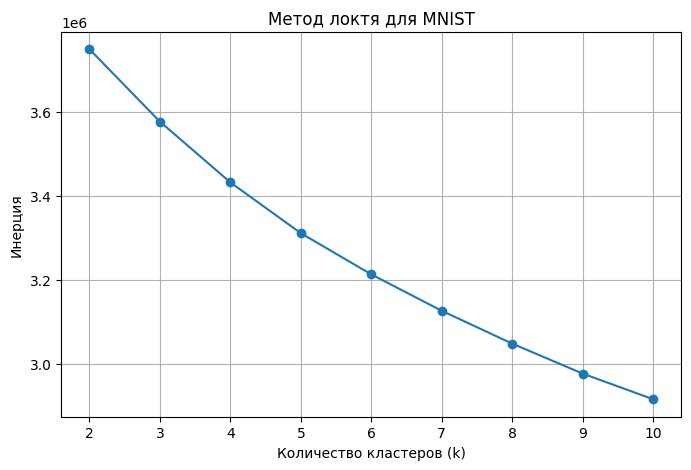

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    inertias,
    marker="o"
)

plt.xlabel("Количество кластеров (k)")
plt.ylabel("Инерция")
plt.title("Метод локтя для MNIST")

plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

In [18]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_pca)

    score = silhouette_score(X_pca, labels)
    silhouette_scores.append(score)

    print(f"k = {k}, silhouette = {score:.4f}")

k = 2, silhouette = 0.1504
k = 3, silhouette = 0.0756
k = 4, silhouette = 0.0642
k = 5, silhouette = 0.0729
k = 6, silhouette = 0.0464
k = 7, silhouette = 0.0507
k = 8, silhouette = 0.0612
k = 9, silhouette = 0.0684
k = 10, silhouette = 0.0758


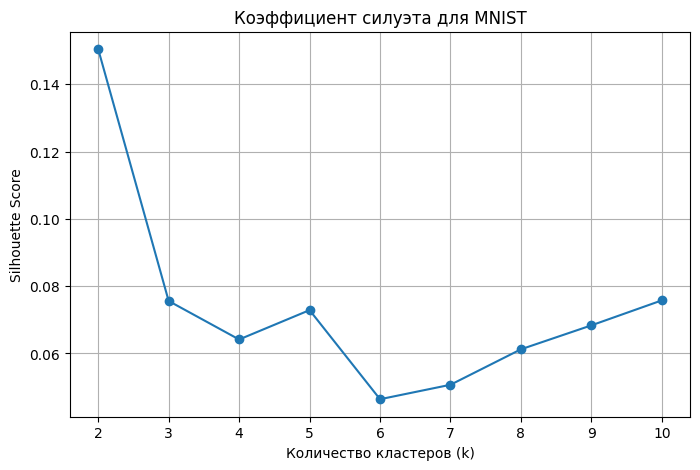

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker="o"
)

plt.xlabel("Количество кластеров (k)")
plt.ylabel("Silhouette Score")
plt.title("Коэффициент силуэта для MNIST")

plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

In [20]:
final_k = 4

kmeans_final = KMeans(
    n_clusters=final_k,
    random_state=42,
    n_init=10
)

clusters = kmeans_final.fit_predict(X_pca)

df["Cluster"] = clusters

print("Итоговое количество кластеров:", final_k)
print("\nКоличество объектов в каждом кластере:")
print(df["Cluster"].value_counts().sort_index())

Итоговое количество кластеров: 4

Количество объектов в каждом кластере:
Cluster
0    2501
1    3334
2    3232
3     933
Name: count, dtype: int64


In [21]:
cluster_profiles = df.groupby("Cluster")[X.columns].mean()

print("Размер таблицы профилей:", cluster_profiles.shape)

display(cluster_profiles.iloc[:, :20].round(2))

Размер таблицы профилей: (4, 784)


,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
Cluster,,,,,,,,,,,,,,,,,,,,
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


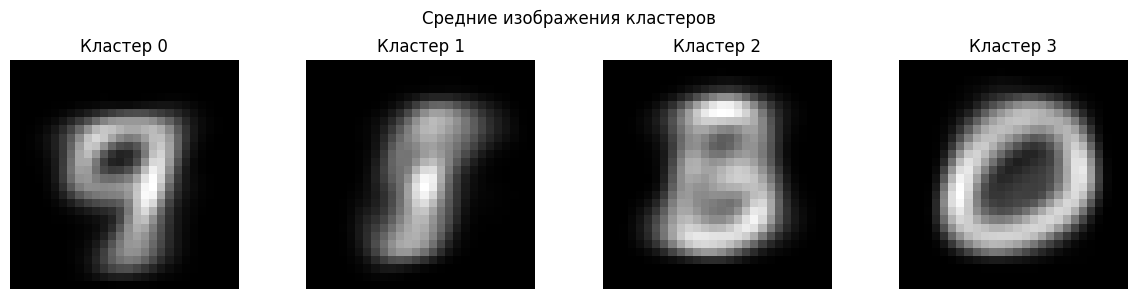

In [22]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3))

for cluster in range(4):
    mean_image = cluster_profiles.loc[cluster].values.reshape(28, 28)

    axes[cluster].imshow(mean_image, cmap="gray")
    axes[cluster].set_title(f"Кластер {cluster}")
    axes[cluster].axis("off")

plt.suptitle("Средние изображения кластеров")
plt.tight_layout()
plt.show()

In [23]:
cluster_digit_table = pd.crosstab(
    df["Cluster"],
    y,
    normalize="index"
) * 100

display(cluster_digit_table.round(2))

,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,0.16,0.00,1.08,2.48,27.15,3.76,0.32,29.15,4.68,31.23
1,1.05,33.86,4.26,6.27,7.53,12.81,4.44,8.70,15.36,5.73
2,9.68,0.19,25.19,22.77,0.50,11.11,19.62,0.19,10.15,0.62
3,67.31,0.00,5.25,0.32,3.86,1.29,18.01,0.32,1.82,1.82


In [24]:
for cluster in sorted(df["Cluster"].unique()):
    digits = y[df["Cluster"] == cluster]

    counts = digits.value_counts()
    main_digit = counts.idxmax()
    percentage = counts.max() / len(digits) * 100

    print(
        f"Кластер {cluster}: "
        f"чаще всего цифра {main_digit} "
        f"({percentage:.2f}%)"
    )

Кластер 0: чаще всего цифра 9 (31.23%)
Кластер 1: чаще всего цифра 1 (33.86%)
Кластер 2: чаще всего цифра 2 (25.19%)
Кластер 3: чаще всего цифра 0 (67.31%)


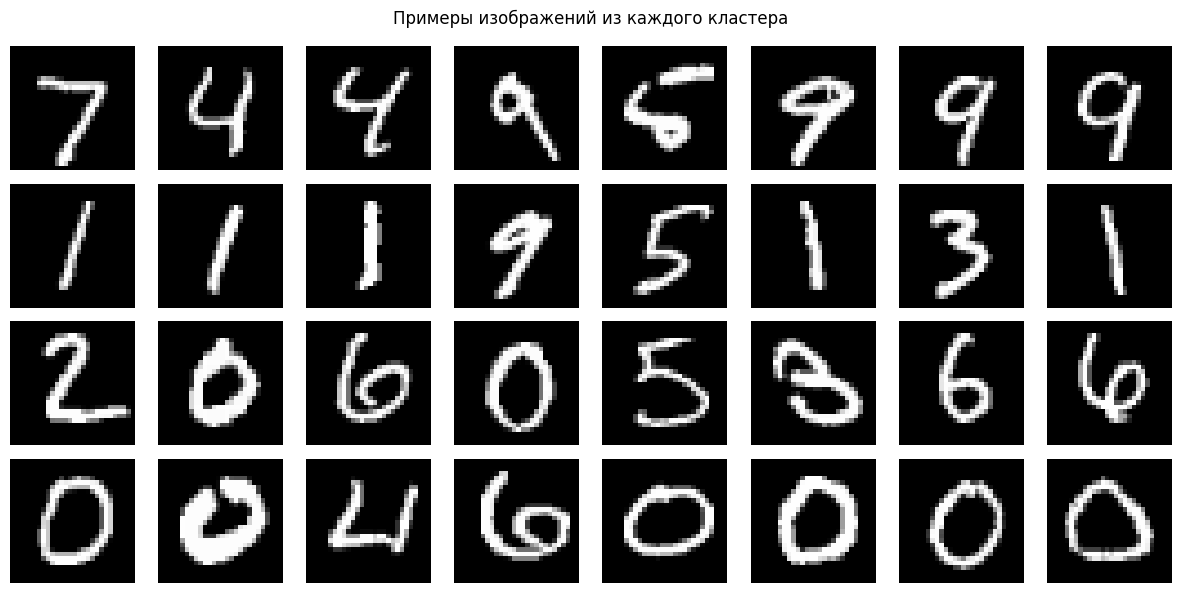

In [25]:
fig, axes = plt.subplots(4, 8, figsize=(12, 6))

for cluster in range(4):
    indices = df.index[df["Cluster"] == cluster][:8]

    for j, idx in enumerate(indices):
        image = X.iloc[idx].values.reshape(28, 28)

        axes[cluster, j].imshow(image, cmap="gray")
        axes[cluster, j].axis("off")

        if j == 0:
            axes[cluster, j].set_ylabel(
                f"Кластер {cluster}",
                fontsize=10
            )

plt.suptitle("Примеры изображений из каждого кластера")
plt.tight_layout()
plt.show()

In [26]:
for cluster in sorted(df["Cluster"].unique()):
    digits = y[df["Cluster"] == cluster]

    counts = digits.value_counts()
    main_digit = counts.idxmax()
    percentage = counts.max() / len(digits) * 100

    print(
        f"Кластер {cluster}: "
        f"чаще всего цифра {main_digit} "
        f"({percentage:.2f}%)"
    )

Кластер 0: чаще всего цифра 9 (31.23%)
Кластер 1: чаще всего цифра 1 (33.86%)
Кластер 2: чаще всего цифра 2 (25.19%)
Кластер 3: чаще всего цифра 0 (67.31%)


In [27]:
cluster_digit_table = pd.crosstab(
    df["Cluster"],
    y,
    normalize="index"
) * 100

display(cluster_digit_table.round(2))

,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,0.16,0.00,1.08,2.48,27.15,3.76,0.32,29.15,4.68,31.23
1,1.05,33.86,4.26,6.27,7.53,12.81,4.44,8.70,15.36,5.73
2,9.68,0.19,25.19,22.77,0.50,11.11,19.62,0.19,10.15,0.62
3,67.31,0.00,5.25,0.32,3.86,1.29,18.01,0.32,1.82,1.82


In [28]:
kmeans_new = KMeans(
    n_clusters=4,
    random_state=123,
    n_init=10
)

clusters_new = kmeans_new.fit_predict(X_pca)

print("Кластеризация с random_state=123 выполнена.")

print("\nРазмеры новых кластеров:")
print(pd.Series(clusters_new).value_counts().sort_index())

Кластеризация с random_state=123 выполнена.

Размеры новых кластеров:
0    3291
1    2460
2     894
3    3355
Name: count, dtype: int64


In [29]:
comparison = pd.crosstab(
    df["Cluster"],
    clusters_new
)

print("Сравнение кластеров:")
display(comparison)

Сравнение кластеров:


col_0,0,1,2,3
Cluster,,,,
0,4,2422,0,75
1,64,0,0,3270
2,3197,26,0,9
3,26,12,894,1


In [30]:
from sklearn.metrics import adjusted_rand_score

ari = adjusted_rand_score(
    df["Cluster"],
    clusters_new
)

print("Adjusted Rand Index:", round(ari, 4))

Adjusted Rand Index: 0.9404


In [31]:
for cluster in sorted(set(clusters_new)):
    digits = y[clusters_new == cluster]

    counts = digits.value_counts()
    main_digit = counts.idxmax()
    percentage = counts.max() / len(digits) * 100

    print(
        f"Новый кластер {cluster}: "
        f"чаще всего цифра {main_digit} "
        f"({percentage:.2f}%)"
    )

Новый кластер 0: чаще всего цифра 2 (25.10%)
Новый кластер 1: чаще всего цифра 9 (31.02%)
Новый кластер 2: чаще всего цифра 0 (69.57%)
Новый кластер 3: чаще всего цифра 1 (33.65%)


In [32]:
summary = pd.DataFrame({
    "Кластер": [0, 1, 2, 3],
    "Количество объектов": [
        (df["Cluster"] == 0).sum(),
        (df["Cluster"] == 1).sum(),
        (df["Cluster"] == 2).sum(),
        (df["Cluster"] == 3).sum()
    ],
    "Основная цифра": [9, 1, 2, 0],
    "Доля основной цифры, %": [31.23, 33.86, 25.19, 67.31],
    "Интерпретация": [
        "Смешанный кластер, преобладают 9, 7 и 4",
        "Смешанный кластер, преобладает 1",
        "Смешанный кластер, преобладают 2, 3 и 6",
        "Наиболее однородный кластер, преобладает 0"
    ]
})

display(summary)

,Кластер,Количество объектов,Основная цифра,"Доля основной цифры, %",Интерпретация
0,0,2501,9,31.23,"Смешанный кластер, преобладают 9, 7 и 4"
1,1,3334,1,33.86,"Смешанный кластер, преобладает 1"
2,2,3232,2,25.19,"Смешанный кластер, преобладают 2, 3 и 6"
3,3,933,0,67.31,"Наиболее однородный кластер, преобладает 0"


In [33]:
print("========== РЕЗУЛЬТАТ ПРАКТИЧЕСКОЙ РАБОТЫ ==========")

print(f"Количество объектов: {len(df)}")
print(f"Количество исходных признаков: {X.shape[1]}")
print(f"Количество признаков после PCA: {X_pca.shape[1]}")
print(f"Выбранное количество кластеров: {final_k}")

print(f"\nЛучший silhouette при k=2: {max(silhouette_scores):.4f}")
print(f"Adjusted Rand Index: {ari:.4f}")

print("\nПрактическая работа выполнена.")

========== РЕЗУЛЬТАТ ПРАКТИЧЕСКОЙ РАБОТЫ ==========
Количество объектов: 10000
Количество исходных признаков: 784
Количество признаков после PCA: 50
Выбранное количество кластеров: 4

Лучший silhouette при k=2: 0.1504
Adjusted Rand Index: 0.9404

Практическая работа выполнена.


1. Метод локтя
Для определения оптимального количества кластеров был построен график зависимости инерции от количества кластеров k от 2 до 10. Наиболее выраженный перелом кривой наблюдается примерно при k=4, после чего уменьшение инерции становится более плавным.

2. Коэффициент силуэта
Коэффициент силуэта был рассчитан для значений k от 2 до 10. Максимальное значение наблюдается при k=2 и составляет приблизительно 0.15. Однако два кластера дают слишком грубое разбиение данных MNIST. Поэтому с учётом содержательной интерпретируемости было выбрано k=4.

3. Выбор количества кластеров
Итоговое количество кластеров — 4. Выбор основан на методе локтя и содержательных соображениях. При k=4 получаются более информативные сегменты, позволяющие выделить группы изображений со схожими формами цифр.

4. Интерпретация кластеров
Кластер 0 содержит 2501 изображение. Наиболее часто в нём встречается цифра 9 (31.23%), однако также значительную долю составляют цифры 7 и 4. Поэтому кластер можно охарактеризовать как смешанный кластер изображений с похожими формами цифр 9, 7 и 4.

Кластер 1 содержит 3334 изображения. Наиболее распространённая цифра — 1 (33.86%). Также присутствуют цифры 8 и 5. Кластер характеризуется преимущественно изображениями с вытянутыми вертикальными формами.

Кластер 2 содержит 3232 изображения. Основная цифра — 2 (25.19%), также значительную долю занимают 3 и 6. Кластер представляет группу похожих изогнутых форм.

Кластер 3 содержит 933 изображения. В нём преобладает цифра 0 (67.31%), поэтому это наиболее однородный кластер. Среднее изображение кластера также визуально напоминает цифру 0.

5. Устойчивость
Для проверки устойчивости кластеризация была повторена с random_state=123. Размеры кластеров изменились незначительно по структуре, а номера кластеров были в основном переставлены. Например, исходный кластер 0 соответствует новому кластеру 1, исходный кластер 1 — новому кластеру 3, исходный кластер 2 — новому кластеру 0, а исходный кластер 3 — новому кластеру 2. Значение Adjusted Rand Index составило 0.9404, что показывает высокую устойчивость полученного разбиения.